In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# Dataset 1: Voltage vs Distance

temps  = [354, 353, 348, 353, 348, 352, 354, 346]
V_offs = [0.110, 0.090, 0.077, 0.082, 0.078, 0.071, 0.067, 0.063]
V_ons  = [1.412, 0.912, 0.690, 0.515, 0.386, 0.332, 0.255, 0.210]
ds     = [20, 25, 30, 35, 40, 45, 50, 55]

data_distance = pd.DataFrame({
    'd [cm]': ds,
    '1/d^2 [cm^{-2}]': [(1 / d**2) for d in ds],
    'T [℃]': temps,
    'V_off [mV]': V_offs,
    'V_on [mV]': V_ons,
    'V_net [mV]': [von - voff for von, voff in zip(V_ons, V_offs)]
})

# Dataset 2: Voltage vs Temperature

temps2 =  [350, 339, 330, 319, 310, 300, 289, 280, 270]
t_kelvins = [(temp + 273) for temp in temps2]
Voffs = [0.025, 0.025, 0.021, 0.016, 0.023, 0.022, 0.023, 0.025, 0.024]
Vons  = [0.65, 0.605, 0.572, 0.535, 0.504, 0.474, 0.445, 0.412, 0.380]

data_temp = pd.DataFrame({
    'T [℃]': temps2,
    'T [K]': t_kelvins,
    'T4 [K4]': [temp**4 for temp in t_kelvins],
    'V_off [mV]': Voffs,
    'V_on [mV]': Vons,
    'V_net [mV]': [np.absolute(Von - Vof) for Von, Vof in zip(Voffs, Vons)]
})

# Dataset 3: Voltage vs Angle
angles = [10, 15, 20, 25, 30, 35, 40, 45, 50]

data_angle = pd.DataFrame({
    'theta [deg]': angles,
    'cos(θ)': [np.cos(np.radians(theta)) for theta in angles],
    'V_net [mV]': [1.438, 1.377, 1.357, 1.266, 1.227, 1.146, 1.015, 0.885, 0.794]
})

In [3]:
data_distance

,d [cm],1/d^2 [cm^{-2}],T [℃],V_off [mV],V_on [mV],V_net [mV]
0,20,0.002500,354,0.110,1.412,1.302
1,25,0.001600,353,0.090,0.912,0.822
2,30,0.001111,348,0.077,0.690,0.613
3,35,0.000816,353,0.082,0.515,0.433
4,40,0.000625,348,0.078,0.386,0.308
5,45,0.000494,352,0.071,0.332,0.261
6,50,0.000400,354,0.067,0.255,0.188
7,55,0.000331,346,0.063,0.210,0.147


In [4]:
data_angle

,theta [deg],cos(θ),V_net [mV]
0,10,0.984808,1.438
1,15,0.965926,1.377
2,20,0.939693,1.357
3,25,0.906308,1.266
4,30,0.866025,1.227
5,35,0.819152,1.146
6,40,0.766044,1.015
7,45,0.707107,0.885
8,50,0.642788,0.794


In [5]:
data_temp

,T [℃],T [K],T4 [K4],V_off [mV],V_on [mV],V_net [mV]
0,350,623,150644120641,0.025,0.650,0.625
1,339,612,140283207936,0.025,0.605,0.580
2,330,603,132211504881,0.021,0.572,0.551
3,319,592,122825015296,0.016,0.535,0.519
4,310,583,115524532321,0.023,0.504,0.481
5,300,573,107799932241,0.022,0.474,0.452
6,289,562,99757432336,0.023,0.445,0.422
7,280,553,93519144481,0.025,0.412,0.387
8,270,543,86935932801,0.024,0.380,0.356


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
import math

def plot_with_stats_table(x, y, xlabel, ylabel,
                          table_bbox=(0.05, 0.55, 0.35, 0.4),
                          watermark_loc=((0.95, 0.05), 'right', 'bottom'),
                          figsize=(8, 6),
                          plot_name=None,
                          slope_unit=''):
    """
    Draw a black-square scatter + thin red regression line,
    with a fully-computed stats table (Origin-like format) and a watermark.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # --- Regression ---
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    r_squared = r_value ** 2
    n = len(x)
    adj_r_sq = 1 - (1 - r_squared) * (n - 1) / (n - 2)
    rss = np.sum((y - (slope * x + intercept)) ** 2)

    # Standard errors of the fit (Origin-style)
    # https://en.wikipedia.org/wiki/Simple_linear_regression#Numerical_example
    x_mean = np.mean(x)
    sxx = np.sum((x - x_mean) ** 2)
    if n > 2:
        s2 = rss / (n - 2)
        se_slope = math.sqrt(s2 / sxx) if sxx > 0 else 0.0
        se_intercept = math.sqrt(s2 * (1.0/n + x_mean**2 / sxx)) if sxx > 0 else 0.0
    else:
        se_slope = se_intercept = 0.0

    # --- Plot ---
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(x, y, 'ks', markersize=8)
    x_fit = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_fit, slope * x_fit + intercept, 'r-', linewidth=0.8)

    ax.set_xlabel(xlabel, fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.tick_params(axis='both', which='major', labelsize=16)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Match the Origin "1.00E+11" style on the x-axis if it's large
    if np.max(np.abs(x)) >= 1e4:
        ax.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))

    # --- Fully-computed table ---
    table_data = [
        ["Equation",              "y = a + b*x"],
        ["Plot",                  plot_name if plot_name else ylabel.split()[0]],
        ["Weight",                "No Weighting"],
        ["Intercept",             f"{intercept:.5f} ± {se_intercept:.5f}"],
        ["Slope",                 f"{slope:.5E} ± {se_slope:.5E}"],
        ["Residual Sum of Squares", f"{rss:.5f}"],
        ["Pearson's r",           f"{r_value:.5f}"],
        ["R-Square (COD)",        f"{r_squared:.5f}"],
        ["Adj. R-Square",         f"{adj_r_sq:.5f}"],
    ]

    table = ax.table(cellText=table_data, loc='upper left',
                     bbox=list(table_bbox), cellLoc='left')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)

    ax.text(watermark_loc[0][0], watermark_loc[0][1],
            'Mohammad Javad Zhianpour\nBlack Body',
            transform=ax.transAxes,
            ha=watermark_loc[1], va=watermark_loc[2],
            fontsize=16)

    plt.tight_layout()
    plt.show()
    return slope, intercept, r_squared

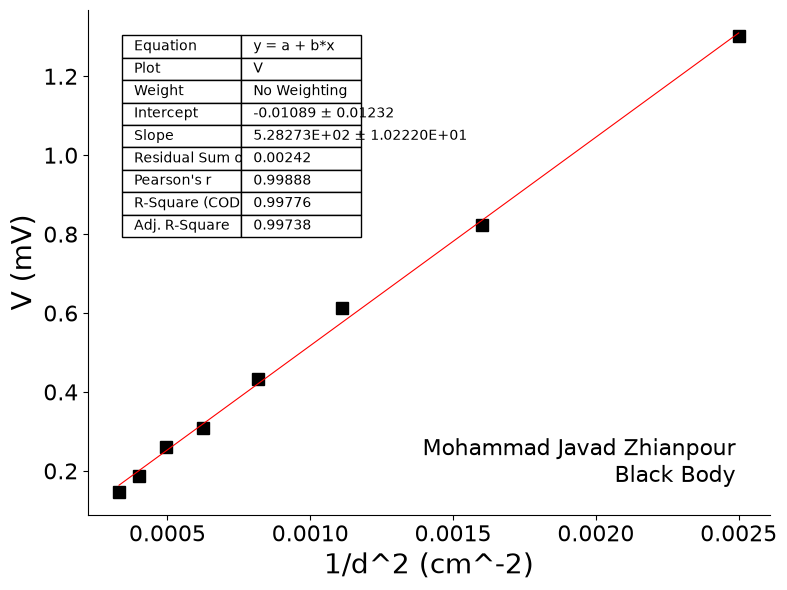

(np.float64(528.2727256490767),
 np.float64(-0.010890185915222728),
 np.float64(0.9977585515002276))

In [14]:
x = data_distance['1/d^2 [cm^{-2}]']
y = data_distance['V_net [mV]']

plot_with_stats_table(
    x, y,
    xlabel='1/d^2 (cm^-2)',
    ylabel='V (mV)',                          # match the screenshot label
    plot_name='V',                            # "Plot | V" row
    table_bbox=(0.05, 0.55, 0.35, 0.4),       # top-left
    watermark_loc=((0.95, 0.05), 'right', 'bottom')
)

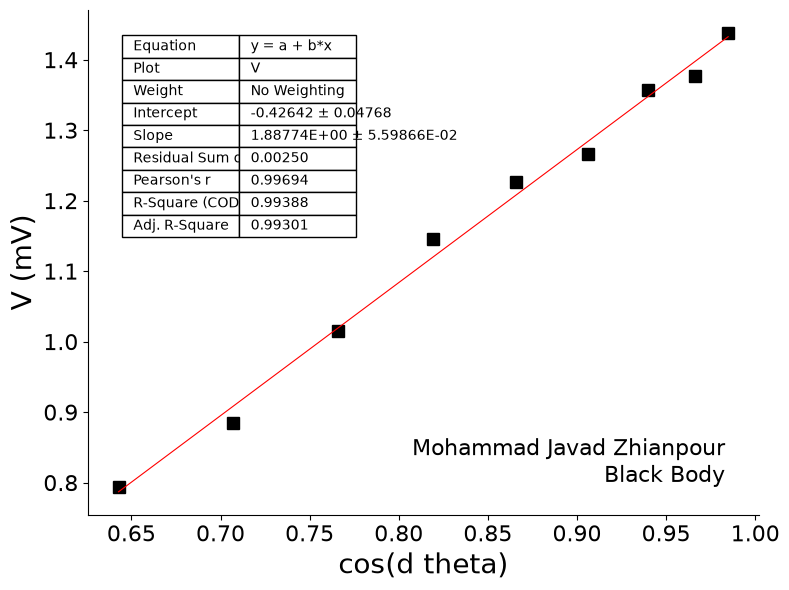

(np.float64(1.8877381547110685),
 np.float64(-0.4264168718811623),
 np.float64(0.9938804915811383))

In [16]:
x = data_angle['cos(θ)']
y = data_angle['V_net [mV]']

plot_with_stats_table(
    x, y,
    xlabel='cos(d theta)',
    ylabel='V (mV)',
    plot_name='V',
    table_bbox=(0.05, 0.55, 0.35, 0.4),       # top-left, like screenshot #3
    watermark_loc=((0.95, 0.05), 'right', 'bottom')
)

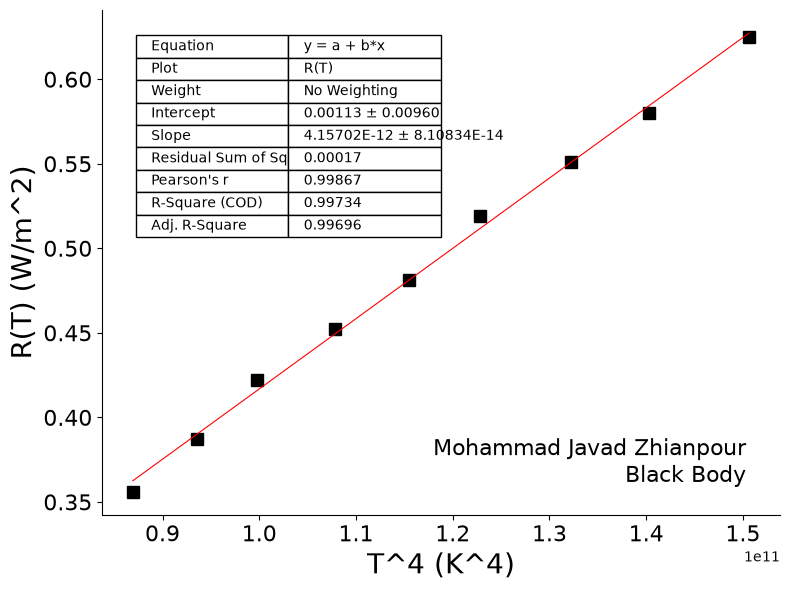

(np.float64(4.157017356096638e-12),
 np.float64(0.001134095980628469),
 np.float64(0.9973439074210798))

In [19]:
x = data_temp['T4 [K4]']
y = data_temp['V_net [mV]']

plot_with_stats_table(
    x, y,
    xlabel='T^4 (K^4)',
    ylabel='R(T) (W/m^2)',
    plot_name='R(T)',
    table_bbox=(0.05, 0.55, 0.45, 0.40),      # top-left
    watermark_loc=((0.95, 0.05), 'right', 'bottom')
)

In [21]:
# ============================================================
# STEPHAN–BOLTZMANN CONSTANT — derived by us, NOT by the LLM.
# ============================================================
from scipy.stats import linregress
import math

# --- 0. Build the SI-column views the report needs -------------
# The base DataFrames (data_temp, data_distance, data_angle) use
# display-friendly column names ('T4 [K4]', 'V_net [mV]', ...).
# We make local views with short names and SI units (V, not mV).

temp_df = data_temp.rename(columns={
    'T4 [K4]'   : 'T4',
    'V_net [mV]': 'V_net_V',
}).copy()
temp_df['V_net_V'] = temp_df['V_net_V'] * 1e-3          # mV -> V

dist_df = data_distance.rename(columns={
    '1/d^2 [cm^{-2}]': 'inv_d2',
    'V_net [mV]'     : 'V_net_V',
}).copy()
dist_df['V_net_V'] = dist_df['V_net_V'] * 1e-3          # mV -> V

ang_df = data_angle.rename(columns={
    'cos(θ)'    : 'cos_theta',
    'V_net [mV]': 'V_net_V',
}).copy()
ang_df['V_net_V'] = ang_df['V_net_V'] * 1e-3            # mV -> V

# --- helper: OLS slope/intercept with correct std errors ------
def ols(x, y):
    """Return slope, intercept, r, se_slope, se_intercept, r2."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    res = linregress(x, y)
    slope, intercept, r = res.slope, res.intercept, res.rvalue
    n   = len(x)
    x_mean = x.mean()
    sxx = np.sum((x - x_mean) ** 2)
    rss = np.sum((y - (slope * x + intercept)) ** 2)
    if n > 2 and sxx > 0:
        s2 = rss / (n - 2)
        se_slope     = math.sqrt(s2 / sxx)
        se_intercept = math.sqrt(s2 * (1.0 / n + x_mean ** 2 / sxx))
    else:
        se_slope = se_intercept = 0.0
    return slope, intercept, r, se_slope, se_intercept, r ** 2

# --- 1. Stefan–Boltzmann fit: V_net vs T^4 (V and K^4) -------
slope_V, intercept_V, r_V, slope_V_err, intercept_V_err, r2_V = \
    ols(temp_df['T4'], temp_df['V_net_V'])

# --- 2. Geometry / sensitivity (from the lab manual) ---------
# d = distance from diaphragm to thermopile, in METERS
# l = diameter of diaphragm, in METERS
# S = thermopile sensitivity, in V / W
#   1 mV/mW = 1e-3 V / 1e-3 W = 1 V/W,  so 16 mV/mW = 16 V/W.
d_m       = 0.20        # 20 cm
l_m       = 0.01        # 1 cm (override with the real diaphragm diameter)
S_V_per_W = 16.0        # 16 mV/mW == 16 V/W

# --- 3. Derivation (all unit algebra written out) ------------
# Physical model (from theory):
#     R(T) = (4 d^2) / (pi l^2) * P
#     P    = V / S
#     R(T) = sigma * T^4
# Combining:
#     V = [ pi l^2 S / (4 d^2) ] * sigma * T^4 + V0
# Therefore:
#     slope_V = pi l^2 S / (4 d^2) * sigma
# =>
#     sigma = slope_V * (4 d^2) / (pi l^2 S)
#
# Unit check:
#   slope_V            : V / K^4
#   4 d^2 / (pi l^2)   : m^2 / m^2 = dimensionless
#   1 / S              : W / V
#   slope_V * (4d^2)/(pi l^2 S) : (V/K^4) * (1) * (W/V) = W / (m^2 K^4)  ✔

sigma_exp = slope_V * (4 * d_m ** 2) / (math.pi * l_m ** 2 * S_V_per_W)

# --- 4. Propagate uncertainty on sigma (slope only) ----------
sigma_err = slope_V_err * (4 * d_m ** 2) / (math.pi * l_m ** 2 * S_V_per_W)

# --- 5. Format with exactly ONE significant figure in err ----
def _one_sig_fig_err(value: float, err: float):
    """Round err to 1 sig fig; round value to the same decimal place."""
    if err == 0 or not np.isfinite(err):
        return f"{value:.3e}", f"{0:.0e}"
    exp = int(math.floor(math.log10(abs(err))))
    decimals = -exp                                    # 1 sig fig in the mantissa
    err_r = round(err, decimals)
    val_r = round(value, decimals)
    fmt = f".{max(decimals, 0)}e"
    return format(val_r, fmt), format(err_r, fmt)

sigma_val_str, sigma_err_str = _one_sig_fig_err(sigma_exp, sigma_err)
sigma_sci_str = f"({sigma_val_str} ± {sigma_err_str}) W/(m^2·K^4)"

# --- 6. Refit the other two plots so the report uses SAME values ----
slope_d, int_d, r_d, se_d, se_int_d, r2_d = ols(dist_df['inv_d2'],  dist_df['V_net_V'])
slope_a, int_a, r_a, se_a, se_int_a, r2_a = ols(ang_df['cos_theta'], ang_df['V_net_V'])

# --- 7. Package everything the report needs ------------------
sigma_report = {
    # Distance fit (V per cm^-2)
    "distance": {
        "slope"         : slope_d,
        "slope_err"     : se_d,
        "intercept"     : int_d,
        "intercept_err" : se_int_d,
        "r2"            : r2_d,
        "n"             : len(dist_df),
    },
    # Angle fit (V per unit cos theta)
    "angle": {
        "slope"         : slope_a,
        "slope_err"     : se_a,
        "intercept"     : int_a,
        "intercept_err" : se_int_a,
        "r2"            : r2_a,
        "n"             : len(ang_df),
    },
    # Stefan-Boltzmann fit (V per K^4)
    "temperature": {
        "slope"         : slope_V,
        "slope_err"     : slope_V_err,
        "intercept"     : intercept_V,
        "intercept_err" : intercept_V_err,
        "r2"            : r2_V,
        "n"             : len(temp_df),
    },
    # Derived constant
    "sigma": {
        "value"       : sigma_exp,
        "uncertainty" : sigma_err,
        "formatted"   : sigma_sci_str,
        "theoretical" : 5.67e-8,
        "unit"        : "W/(m^2·K^4)",
        "geometry"    : {"d_m": d_m, "l_m": l_m, "S_V_per_W": S_V_per_W},
    },
}

# --- 8. Sanity print (for you, not for the report) -----------
print("Fit: V_net = slope·T⁴ + intercept")
print(f"  slope     = {slope_V:.4e} V/K⁴")
print(f"  slope_err = {slope_V_err:.4e} V/K⁴")
print(f"  intercept = {intercept_V:.4e} V")
print(f"  R²        = {r2_V:.5f}")
print()
print(f"σ_exp  = {sigma_exp:.4e} ± {sigma_err:.1e}  W/(m²·K⁴)")
print(f"σ_theo = {5.67e-8:.4e}  W/(m²·K⁴)")
print(f"ratio  = {sigma_exp / 5.67e-8:.4f}")

Fit: V_net = slope·T⁴ + intercept
  slope     = 4.1570e-15 V/K⁴
  slope_err = 8.1083e-17 V/K⁴
  intercept = 1.1341e-06 V
  R²        = 0.99734

σ_exp  = 1.3232e-13 ± 2.6e-15  W/(m²·K⁴)
σ_theo = 5.6700e-08  W/(m²·K⁴)
ratio  = 0.0000
